# Hyderabad Infrastructure Points — Data Analysis and Spatial Clustering

**Project:** Integrated Urban Risk Analytics and Resource Prioritization System  
**Dataset:** `infrastructure_points.csv`  
**Purpose:** Audit infrastructure assets, understand their spatial/category distribution, compare exploratory spatial clustering algorithms, and derive transparent nearby-resource indicators.

## What this notebook does

1. Locate and load the project CSV without changing the original file.
2. Resolve common column-name variations for coordinates, category, name, subtype and identifiers.
3. Audit missing values, duplicates, data types and geographic validity.
4. Explore asset categories and their geographic distribution.
5. Compare **K-Means** and **DBSCAN** for exploratory spatial grouping.
6. Calculate nearby asset, hospital, fire-station and building counts around each asset.
7. Save cleaned data, summaries, cluster assignments and an analysis summary.

## Important interpretation limits

- This dataset has no independently verified target column for predicting infrastructure adequacy or service outcomes. Therefore, this notebook does **not** train a supervised classifier or regressor.
- K-Means and DBSCAN identify spatial groupings only. Cluster IDs are arbitrary and are **not** low/medium/high infrastructure-risk labels.
- Counts within a radius describe the supplied dataset's mapped assets. They do not prove that every real-world facility has been mapped or is operational.
- Nearby counts include the focal asset itself where it falls inside the radius. This is stated explicitly so counts are not mistaken for counts of other assets only.
- No asset is deleted merely because another asset has the same coordinates. Different OSM features can share a location.

## 1. Import libraries and locate the dataset

The notebook searches both likely project locations:

- `data/processed/infrastructure/infrastructure_points.csv`
- `data/processed/infrastructure_points.csv`

The output folder is created under `data/processed/infrastructure/`.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import BallTree

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
EARTH_RADIUS_KM = 6371.0088

HERE = Path.cwd().resolve()
PROJECT_ROOT = None
INFRA_FILE = None

for folder in [HERE, *HERE.parents]:
    candidates = [
        folder / "data" / "processed" / "infrastructure" / "infrastructure_points.csv",
        folder / "data" / "processed" / "infrastructure_points.csv",
    ]
    for candidate in candidates:
        if candidate.is_file():
            PROJECT_ROOT = folder
            INFRA_FILE = candidate
            break
    if PROJECT_ROOT is not None:
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate infrastructure_points.csv. Expected it in "
        "data/processed/infrastructure/ or data/processed/."
    )

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "infrastructure" / "infrastructure_points_experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Input file:", INFRA_FILE)
print("Output directory:", OUTPUT_DIR)

Project root: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Input file: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\infrastructure_points.csv
Output directory: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\infrastructure_points_experiments


## 2. Load the source dataset

The raw dataframe is retained as `raw_infrastructure`. All cleaning is performed on a separate working copy.

In [2]:
raw_infrastructure = pd.read_csv(INFRA_FILE, encoding="utf-8-sig", low_memory=False)
infrastructure = raw_infrastructure.copy()

print("Dataset loaded successfully")
print("Shape:", infrastructure.shape)
print("Columns:")
print(infrastructure.columns.tolist())

display(infrastructure.head())

Dataset loaded successfully
Shape: (2083, 6)
Columns:
['osm_id', 'category', 'name', 'subtype', 'latitude', 'longitude']


,osm_id,category,name,subtype,latitude,longitude
0,relation/5321005,hospital,Shadan Hospital,hospital,17.352109,78.373614
1,relation/5330163,hospital,Nizams Institute of Medical Sciences Hospital ...,hospital,17.422625,78.453436
2,relation/11902466,hospital,AIG HOSPITALS,hospital,17.443208,78.366195
3,way/31549640,hospital,Axon Hospital,hospital,17.439328,78.442376
4,way/116037991,hospital,Virinchi Hospitals,hospital,17.408080,78.451495


## 3. Resolve important columns

Column names differ across OSM exports and project preprocessing scripts. This cell looks for common alternatives. Latitude and longitude are required. Category is also required for category-level summaries; if it is absent, the cell tries common OSM tag columns.

In [3]:
def normalise_column_name(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())


def find_column(columns, candidates):
    lookup = {normalise_column_name(col): col for col in columns}
    for candidate in candidates:
        key = normalise_column_name(candidate)
        if key in lookup:
            return lookup[key]
    return None

column_map = {
    "latitude": find_column(infrastructure.columns, ["latitude", "lat", "point_lat", "grid_lat"]),
    "longitude": find_column(infrastructure.columns, ["longitude", "lon", "lng", "point_lon", "grid_lon"]),
    "category": find_column(infrastructure.columns, ["category", "asset_category", "asset_type", "type"]),
    "asset_name": find_column(infrastructure.columns, ["asset_name", "name", "name_en", "facility_name"]),
    "subtype": find_column(infrastructure.columns, ["subtype", "sub_type", "feature_subtype", "amenity", "building", "healthcare", "emergency"]),
    "asset_id": find_column(infrastructure.columns, ["asset_id", "id", "feature_id"]),
    "osm_id": find_column(infrastructure.columns, ["osm_id", "osmid", "element_id"]),
    "dataset_id": find_column(infrastructure.columns, ["dataset_id", "source_dataset_id"]),
}

print("Resolved columns:")
for standard_name, source_name in column_map.items():
    print(f"{standard_name:12s} -> {source_name}")

missing_required = [name for name in ["latitude", "longitude", "category"] if column_map[name] is None]
if missing_required:
    raise ValueError(
        f"Could not resolve required columns: {missing_required}. "
        "Check the printed source column names and update column_map candidates."
    )

Resolved columns:
latitude     -> latitude
longitude    -> longitude
category     -> category
asset_name   -> name
subtype      -> subtype
asset_id     -> None
osm_id       -> osm_id
dataset_id   -> None


## 4. Initial data-quality audit

This audit reports missing values, full-row duplicates, duplicate identifiers, and coordinate validity. Duplicate coordinates are reported separately because multiple assets can legitimately share a location.

In [4]:
print("Dataset information:")
infrastructure.info()

print("\nMissing values:")
display(infrastructure.isna().sum().to_frame("missing_count"))

print("\nMissing percentage:")
display((infrastructure.isna().mean() * 100).round(2).to_frame("missing_percent"))

print("\nFull duplicate rows:", int(infrastructure.duplicated().sum()))

asset_id_col = column_map["asset_id"]
osm_id_col = column_map["osm_id"]
if asset_id_col:
    print("Duplicate asset IDs:", int(infrastructure[asset_id_col].duplicated().sum()))
if osm_id_col:
    print("Duplicate OSM IDs:", int(infrastructure[osm_id_col].duplicated().sum()))

lat_col = column_map["latitude"]
lon_col = column_map["longitude"]
coord_preview = infrastructure[[lat_col, lon_col]].copy()
coord_preview[lat_col] = pd.to_numeric(coord_preview[lat_col], errors="coerce")
coord_preview[lon_col] = pd.to_numeric(coord_preview[lon_col], errors="coerce")
valid_geo = (
    coord_preview[lat_col].notna()
    & coord_preview[lon_col].notna()
    & coord_preview[lat_col].between(-90, 90)
    & coord_preview[lon_col].between(-180, 180)
)
print("Rows with valid geographic coordinates:", int(valid_geo.sum()), "/", len(infrastructure))
print("Unique coordinate pairs:", int(coord_preview.loc[valid_geo].drop_duplicates().shape[0]))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2083 entries, 0 to 2082
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   osm_id     2083 non-null   str    
 1   category   2083 non-null   str    
 2   name       1495 non-null   str    
 3   subtype    2083 non-null   str    
 4   latitude   2083 non-null   float64
 5   longitude  2083 non-null   float64
dtypes: float64(2), str(4)
memory usage: 193.1 KB

Missing values:


,missing_count
osm_id,0
category,0
name,588
subtype,0
latitude,0
longitude,0



Missing percentage:


,missing_percent
osm_id,0.00
category,0.00
name,28.23
subtype,0.00
latitude,0.00
longitude,0.00



Full duplicate rows: 0
Duplicate OSM IDs: 0
Rows with valid geographic coordinates: 2083 / 2083
Unique coordinate pairs: 2081


## 5. Create a clean, standardised analysis dataframe

The output retains the original source columns and adds standard columns `latitude`, `longitude`, `category`, `asset_name`, `subtype`, `asset_id` and `osm_id` where available. Invalid coordinates are saved separately for review and excluded from spatial analysis. Only exact full-row duplicates are removed.

In [5]:
clean = infrastructure.copy()
clean["latitude"] = pd.to_numeric(clean[lat_col], errors="coerce")
clean["longitude"] = pd.to_numeric(clean[lon_col], errors="coerce")
clean["category"] = clean[column_map["category"]].astype("string").str.strip()
clean["category"] = clean["category"].replace("", pd.NA).fillna("unknown")

for standard_name in ["asset_name", "subtype", "asset_id", "osm_id", "dataset_id"]:
    source_name = column_map.get(standard_name)
    if source_name is not None:
        clean[standard_name] = clean[source_name]

invalid_coordinate_mask = (
    clean["latitude"].isna()
    | clean["longitude"].isna()
    | ~clean["latitude"].between(-90, 90)
    | ~clean["longitude"].between(-180, 180)
)
invalid_coordinate_rows = clean.loc[invalid_coordinate_mask].copy()

analysis = clean.loc[~invalid_coordinate_mask].copy()
analysis = analysis.drop_duplicates().reset_index(drop=True)

if analysis.empty:
    raise ValueError("No rows with valid latitude/longitude remain after validation.")

print("Original rows:", len(raw_infrastructure))
print("Invalid-coordinate rows:", len(invalid_coordinate_rows))
print("Exact duplicate rows removed:", len(clean.loc[~invalid_coordinate_mask]) - len(analysis))
print("Rows available for analysis:", len(analysis))
print("Category values:", analysis["category"].nunique())

display(analysis[["latitude", "longitude", "category"]].head())

Original rows: 2083
Invalid-coordinate rows: 0
Exact duplicate rows removed: 0
Rows available for analysis: 2083
Category values: 3


,latitude,longitude,category
0,17.352109,78.373614,hospital
1,17.422625,78.453436,hospital
2,17.443208,78.366195,hospital
3,17.439328,78.442376,hospital
4,17.408080,78.451495,hospital


## 6. Descriptive statistics and geographic extent

In [6]:
print("Numerical summary:")
display(analysis.select_dtypes(include=np.number).describe().T)

print("\nGeographic extent:")
geographic_extent = pd.DataFrame({
    "minimum": [analysis["latitude"].min(), analysis["longitude"].min()],
    "maximum": [analysis["latitude"].max(), analysis["longitude"].max()],
    "mean": [analysis["latitude"].mean(), analysis["longitude"].mean()],
}, index=["latitude", "longitude"])
display(geographic_extent)

print("\nCategory counts:")
category_counts = analysis["category"].value_counts().rename_axis("category").reset_index(name="asset_count")
display(category_counts.head(30))

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
latitude,2083.0,17.433241,0.049697,17.259954,17.399000,17.437678,17.474827,17.545873
longitude,2083.0,78.444410,0.081602,78.252448,78.384105,78.448572,78.508954,78.632292



Geographic extent:


,minimum,maximum,mean
latitude,17.259954,17.545873,17.433241
longitude,78.252448,78.632292,78.444410



Category counts:


,category,asset_count
0,hospital,1073
1,building,1003
2,fire_station,7


## 7. Infrastructure category distribution

The chart shows the most common categories. It is a descriptive summary of the supplied point dataset, not a measure of service adequacy.

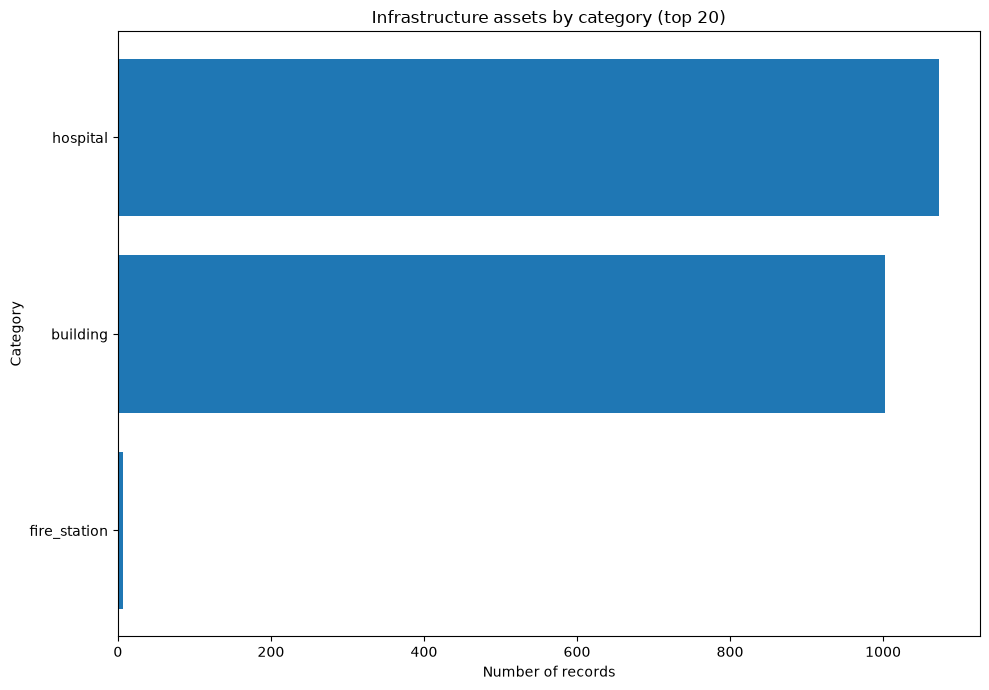

,asset_count
subtype,
hospital,1126
commercial,591
school,285
university,28
industrial,24
fire_station,7
public,5
events_venue,3
conference_centre,3


In [7]:
plot_categories = category_counts.head(20).sort_values("asset_count", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(plot_categories["category"].astype(str), plot_categories["asset_count"])
plt.title("Infrastructure assets by category (top 20)")
plt.xlabel("Number of records")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

if "subtype" in analysis.columns:
    subtype_counts = analysis["subtype"].fillna("Unknown").astype(str).value_counts().head(20)
    display(subtype_counts.rename_axis("subtype").to_frame("asset_count"))

## 8. Geographic distribution of infrastructure points

The following is a longitude/latitude scatter plot. It is useful for checking coverage and visible concentrations. It is not a street-level basemap.

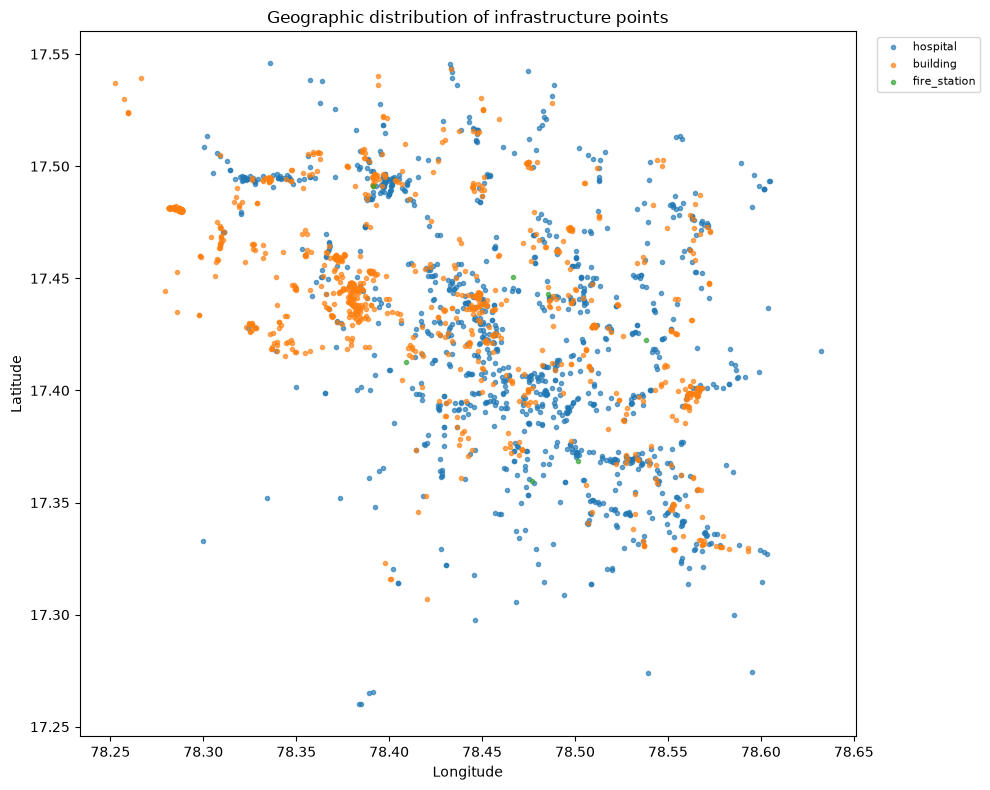

In [8]:
TOP_CATEGORY_COUNT = 10
top_categories = analysis["category"].value_counts().head(TOP_CATEGORY_COUNT).index
map_data = analysis.copy()
map_data["plot_category"] = np.where(map_data["category"].isin(top_categories), map_data["category"], "Other categories")

plt.figure(figsize=(10, 8))
for category in map_data["plot_category"].value_counts().index:
    part = map_data[map_data["plot_category"] == category]
    plt.scatter(part["longitude"], part["latitude"], s=9, alpha=0.65, label=str(category))
plt.title("Geographic distribution of infrastructure points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Prepare local projected coordinates for clustering

Latitude/longitude are angular units. For this city-scale exploratory analysis, convert them to approximate local kilometres around the dataset's median location. This avoids treating one degree of longitude as the same ground distance as one degree of latitude.

In [9]:
REFERENCE_LAT = float(analysis["latitude"].median())
REFERENCE_LON = float(analysis["longitude"].median())

analysis["x_km"] = (
    (analysis["longitude"] - REFERENCE_LON)
    * 111.320
    * np.cos(np.radians(REFERENCE_LAT))
)
analysis["y_km"] = (analysis["latitude"] - REFERENCE_LAT) * 110.574

XY_KM = analysis[["x_km", "y_km"]].to_numpy(dtype=float)
unique_xy = np.unique(XY_KM, axis=0).shape[0]
print("Reference latitude:", REFERENCE_LAT)
print("Reference longitude:", REFERENCE_LON)
print("Unique spatial positions:", unique_xy)
print("Projected coordinate shape:", XY_KM.shape)

Reference latitude: 17.4376777
Reference longitude: 78.4485716
Unique spatial positions: 2081
Projected coordinate shape: (2083, 2)


## 10. K-Means clustering comparison

K-Means is evaluated for several values of `k`. Silhouette score describes separation in the projected spatial coordinates. It is **not classification accuracy**. The best silhouette row is only an exploratory candidate; cluster usefulness should also be checked against the map and cluster sizes.

In [10]:
kmeans_rows = []
kmeans_labels_by_k = {}

max_k = min(8, unique_xy - 1, len(analysis) - 1)
if max_k < 2:
    print("Not enough distinct spatial positions for K-Means silhouette comparison.")
else:
    for k in range(2, max_k + 1):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
        labels = model.fit_predict(XY_KM)
        n_labels = len(np.unique(labels))
        score = silhouette_score(XY_KM, labels) if 1 < n_labels < len(labels) else np.nan
        kmeans_rows.append({
            "algorithm": "K-Means",
            "requested_k": int(k),
            "n_clusters": int(n_labels),
            "silhouette_score": float(score) if pd.notna(score) else np.nan,
            "inertia": float(model.inertia_),
            "clustered_records": int(len(labels)),
            "noise_records": 0,
        })
        kmeans_labels_by_k[k] = labels

kmeans_comparison = pd.DataFrame(kmeans_rows)
display(kmeans_comparison.sort_values("silhouette_score", ascending=False) if not kmeans_comparison.empty else kmeans_comparison)

,algorithm,requested_k,n_clusters,silhouette_score,inertia,clustered_records,noise_records
0,K-Means,2,2,0.482132,92821.670014,2083,0
6,K-Means,8,8,0.441095,23056.134967,2083,0
4,K-Means,6,6,0.439631,31071.420146,2083,0
5,K-Means,7,7,0.436561,26193.899735,2083,0
3,K-Means,5,5,0.416456,37764.521173,2083,0
2,K-Means,4,4,0.415663,50476.742475,2083,0
1,K-Means,3,3,0.388202,65898.462239,2083,0


## 11. DBSCAN clustering comparison

DBSCAN is distance-based and can mark sparse observations as noise (`-1`). The `eps` values below are expressed in kilometres because clustering uses the local projected coordinates. A valid silhouette score is calculated only when the non-noise subset contains at least two clusters and fewer clusters than records.

In [11]:
dbscan_rows = []
dbscan_labels_by_params = {}

DBSCAN_EPS_KM = [0.25, 0.5, 0.75, 1.0, 1.5]
DBSCAN_MIN_SAMPLES = 5

for eps_km in DBSCAN_EPS_KM:
    model = DBSCAN(eps=eps_km, min_samples=DBSCAN_MIN_SAMPLES)
    labels = model.fit_predict(XY_KM)
    non_noise = labels != -1
    valid_labels = labels[non_noise]
    n_clusters = len(set(valid_labels))
    noise_count = int((~non_noise).sum())
    score = np.nan
    if n_clusters >= 2 and non_noise.sum() > n_clusters:
        score = silhouette_score(XY_KM[non_noise], valid_labels)
    dbscan_rows.append({
        "algorithm": "DBSCAN",
        "eps_km": eps_km,
        "min_samples": DBSCAN_MIN_SAMPLES,
        "n_clusters_excluding_noise": int(n_clusters),
        "silhouette_non_noise": float(score) if pd.notna(score) else np.nan,
        "clustered_records": int(non_noise.sum()),
        "noise_records": noise_count,
        "noise_percent": round(noise_count / len(labels) * 100, 2),
    })
    dbscan_labels_by_params[eps_km] = labels

dbscan_comparison = pd.DataFrame(dbscan_rows)
display(dbscan_comparison)

,algorithm,eps_km,min_samples,n_clusters_excluding_noise,silhouette_non_noise,clustered_records,noise_records,noise_percent
0,DBSCAN,0.25,5,78,0.686265,1055,1028,49.35
1,DBSCAN,0.50,5,71,0.411167,1706,377,18.10
2,DBSCAN,0.75,5,36,0.126778,1919,164,7.87
3,DBSCAN,1.00,5,21,-0.142232,2001,82,3.94
4,DBSCAN,1.50,5,8,-0.120522,2039,44,2.11


## 12. Select exploratory cluster assignments and visualise them

The K-Means configuration with the highest valid silhouette score is selected for a descriptive map. DBSCAN is selected similarly among configurations with a valid non-noise silhouette; if none qualifies, the first configured DBSCAN result is retained for inspection. These are **not deployment-approved risk models**.

Selected exploratory K-Means k: 2
Selected exploratory DBSCAN eps (km): 0.25


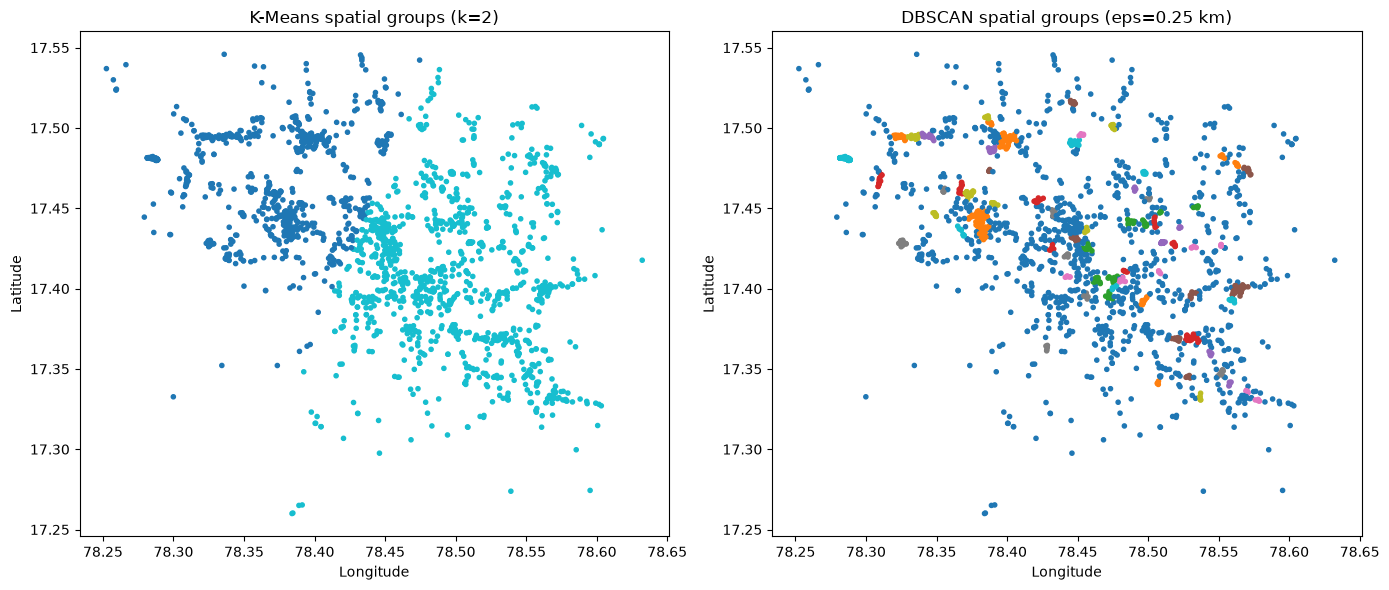

In [12]:
analysis["kmeans_cluster"] = -1
selected_k = None
if not kmeans_comparison.empty and kmeans_comparison["silhouette_score"].notna().any():
    selected_row = kmeans_comparison.loc[kmeans_comparison["silhouette_score"].idxmax()]
    selected_k = int(selected_row["requested_k"])
    analysis["kmeans_cluster"] = kmeans_labels_by_k[selected_k]
    print("Selected exploratory K-Means k:", selected_k)
else:
    print("No valid K-Means selection was available.")

analysis["dbscan_cluster"] = -1
selected_eps = None
valid_dbscan = dbscan_comparison[dbscan_comparison["silhouette_non_noise"].notna()]
if not valid_dbscan.empty:
    selected_eps = float(valid_dbscan.loc[valid_dbscan["silhouette_non_noise"].idxmax(), "eps_km"])
else:
    selected_eps = DBSCAN_EPS_KM[0]
analysis["dbscan_cluster"] = dbscan_labels_by_params[selected_eps]
print("Selected exploratory DBSCAN eps (km):", selected_eps)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(analysis["longitude"], analysis["latitude"], c=analysis["kmeans_cluster"], s=9, cmap="tab10")
axes[0].set_title(f"K-Means spatial groups (k={selected_k})" if selected_k else "K-Means spatial groups")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

axes[1].scatter(analysis["longitude"], analysis["latitude"], c=analysis["dbscan_cluster"], s=9, cmap="tab10")
axes[1].set_title(f"DBSCAN spatial groups (eps={selected_eps} km)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 13. Inspect cluster sizes and category profiles

In [13]:
print("K-Means cluster sizes:")
display(analysis["kmeans_cluster"].value_counts().sort_index().rename_axis("cluster").to_frame("asset_count"))

print("DBSCAN cluster sizes (-1 means noise):")
display(analysis["dbscan_cluster"].value_counts().sort_index().rename_axis("cluster").to_frame("asset_count"))

kmeans_category_profile = pd.crosstab(analysis["kmeans_cluster"], analysis["category"])
display(kmeans_category_profile)

# Save category profile for later review.
kmeans_category_profile.to_csv(OUTPUT_DIR / "infrastructure_kmeans_category_profile.csv")

K-Means cluster sizes:


,asset_count
cluster,
0,870
1,1213


DBSCAN cluster sizes (-1 means noise):


,asset_count
cluster,
-1,1028
0,11
1,64
2,9
3,6
...,...
73,6
74,5
75,6


category,building,fire_station,hospital
kmeans_cluster,,,
0,568,2,300
1,435,5,773


## 14. Calculate nearby-resource counts

For each asset location, count all supplied infrastructure points within a 1 km radius. Also calculate counts for categories whose text contains `hospital`, `fire` plus `station`, or `building`. These are proximity indicators based on the source dataset, not verified service coverage or travel-time accessibility.

In [14]:
RADIUS_KM = 1.0
coords_radians = np.radians(analysis[["latitude", "longitude"]].to_numpy(dtype=float))
asset_tree = BallTree(coords_radians, metric="haversine")
neighbor_indices = asset_tree.query_radius(coords_radians, r=RADIUS_KM / EARTH_RADIUS_KM)

analysis["nearby_asset_count_1km"] = np.fromiter((len(idx) for idx in neighbor_indices), dtype=int)

category_text = analysis["category"].astype(str).str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True)
hospital_mask = category_text.str.contains("hospital", regex=False).to_numpy()
fire_station_mask = (
    category_text.str.contains("fire_station", regex=False)
    | (category_text.str.contains("fire", regex=False) & category_text.str.contains("station", regex=False))
).to_numpy()
building_mask = category_text.str.contains("building", regex=False).to_numpy()

analysis["nearby_hospital_count_1km"] = np.fromiter((int(hospital_mask[idx].sum()) for idx in neighbor_indices), dtype=int)
analysis["nearby_fire_station_count_1km"] = np.fromiter((int(fire_station_mask[idx].sum()) for idx in neighbor_indices), dtype=int)
analysis["nearby_building_count_1km"] = np.fromiter((int(building_mask[idx].sum()) for idx in neighbor_indices), dtype=int)

print("Nearby-count columns created. Counts include the focal point if it matches the category and lies within 1 km.")
display(analysis[["category", "nearby_asset_count_1km", "nearby_hospital_count_1km", "nearby_fire_station_count_1km", "nearby_building_count_1km"]].head())

display(analysis[["nearby_asset_count_1km", "nearby_hospital_count_1km", "nearby_fire_station_count_1km", "nearby_building_count_1km"]].describe().T)

Nearby-count columns created. Counts include the focal point if it matches the category and lies within 1 km.


,category,nearby_asset_count_1km,nearby_hospital_count_1km,nearby_fire_station_count_1km,nearby_building_count_1km
0,hospital,1,1,0,0
1,hospital,51,35,0,16
2,hospital,24,7,0,17
3,hospital,72,26,0,46
4,hospital,22,16,0,6


,count,mean,std,min,25%,50%,75%,max
nearby_asset_count_1km,2083.0,32.975996,31.057481,1.0,12.0,21.0,48.5,123.0
nearby_hospital_count_1km,2083.0,11.819971,11.055347,0.0,4.0,9.0,16.0,55.0
nearby_fire_station_count_1km,2083.0,0.072012,0.258569,0.0,0.0,0.0,0.0,1.0
nearby_building_count_1km,2083.0,21.084013,31.042039,0.0,3.0,8.0,21.0,123.0


## 15. Distance to nearest hospitals and fire stations

Distances are calculated using the haversine distance on geographic coordinates. A missing value means the source dataset contains no point classified with that category text; it does not mean there is no such facility in the real city.

In [15]:
def nearest_category_distance_km(base_coords_rad, source_mask):
    if int(source_mask.sum()) == 0:
        return np.full(len(base_coords_rad), np.nan)
    source_tree = BallTree(base_coords_rad[source_mask], metric="haversine")
    distances_rad, _ = source_tree.query(base_coords_rad, k=1)
    return distances_rad[:, 0] * EARTH_RADIUS_KM

analysis["nearest_hospital_distance_km"] = nearest_category_distance_km(coords_radians, hospital_mask)
analysis["nearest_fire_station_distance_km"] = nearest_category_distance_km(coords_radians, fire_station_mask)

display(analysis[["nearest_hospital_distance_km", "nearest_fire_station_distance_km"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
nearest_hospital_distance_km,2083.0,0.344989,0.731811,0.0,0.000000,0.000000,0.313980,5.894918
nearest_fire_station_distance_km,2083.0,4.492663,2.855880,0.0,2.617983,3.861649,5.648598,15.550905


## 16. Visualise nearby resource indicators

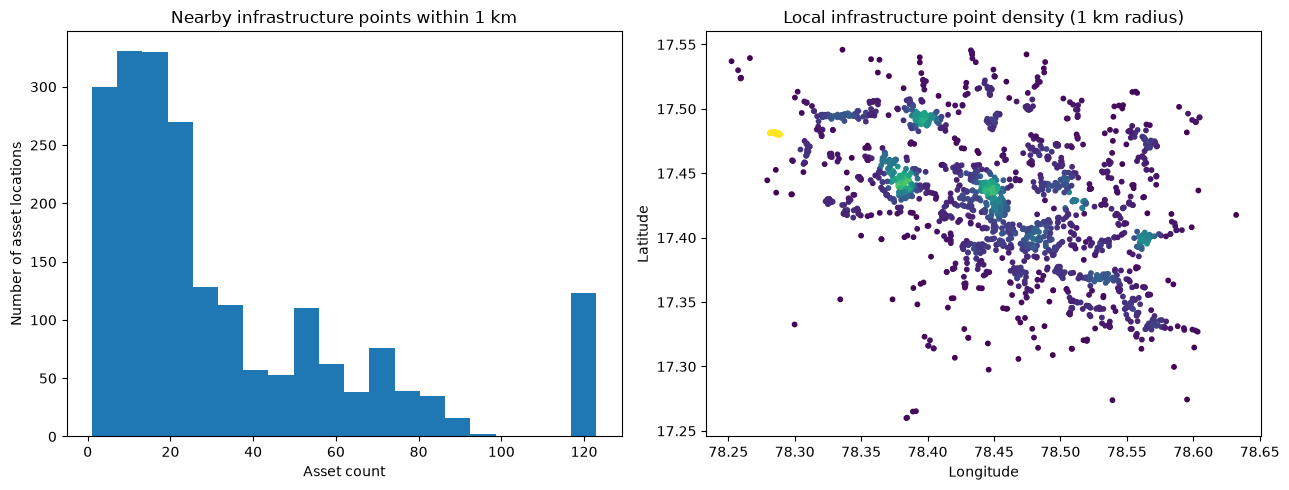

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(analysis["nearby_asset_count_1km"], bins=20)
axes[0].set_title("Nearby infrastructure points within 1 km")
axes[0].set_xlabel("Asset count")
axes[0].set_ylabel("Number of asset locations")

axes[1].scatter(
    analysis["longitude"], analysis["latitude"],
    c=analysis["nearby_asset_count_1km"], s=10, cmap="viridis"
)
axes[1].set_title("Local infrastructure point density (1 km radius)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 17. Save cleaned data, invalid rows, comparisons and summary

The original CSV is not overwritten. All generated files are written to `data/processed/infrastructure/infrastructure_points_experiments/`.

In [17]:
clean_file = OUTPUT_DIR / "infrastructure_points_clean.csv"
invalid_file = OUTPUT_DIR / "infrastructure_points_invalid_coordinates.csv"
category_file = OUTPUT_DIR / "infrastructure_category_summary.csv"
kmeans_file = OUTPUT_DIR / "infrastructure_kmeans_comparison.csv"
dbscan_file = OUTPUT_DIR / "infrastructure_dbscan_comparison.csv"
clustered_file = OUTPUT_DIR / "infrastructure_points_with_clusters_and_density.csv"
summary_file = OUTPUT_DIR / "infrastructure_points_analysis_summary.json"

analysis.to_csv(clean_file, index=False)
invalid_coordinate_rows.to_csv(invalid_file, index=False)
category_counts.to_csv(category_file, index=False)
kmeans_comparison.to_csv(kmeans_file, index=False)
dbscan_comparison.to_csv(dbscan_file, index=False)
analysis.to_csv(clustered_file, index=False)

summary = {
    "source_file": str(INFRA_FILE),
    "source_records": int(len(raw_infrastructure)),
    "analysis_records": int(len(analysis)),
    "invalid_coordinate_records": int(len(invalid_coordinate_rows)),
    "exact_duplicate_rows_removed": int(len(clean.loc[~invalid_coordinate_mask]) - len(analysis)),
    "unique_categories": int(analysis["category"].nunique()),
    "unique_coordinate_pairs": int(analysis[["latitude", "longitude"]].drop_duplicates().shape[0]),
    "latitude_min": float(analysis["latitude"].min()),
    "latitude_max": float(analysis["latitude"].max()),
    "longitude_min": float(analysis["longitude"].min()),
    "longitude_max": float(analysis["longitude"].max()),
    "selected_kmeans_k": int(selected_k) if selected_k is not None else None,
    "selected_dbscan_eps_km": float(selected_eps) if selected_eps is not None else None,
    "nearby_count_radius_km": float(RADIUS_KM),
    "supervised_model_trained": False,
    "cluster_interpretation": "Exploratory spatial groups only; not validated infrastructure-risk labels.",
    "outputs_directory": str(OUTPUT_DIR),
}

with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("ANALYSIS SUMMARY")
print(json.dumps(summary, indent=4))
print("\nGenerated files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

ANALYSIS SUMMARY
{
    "source_file": "C:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\infrastructure\\infrastructure_points.csv",
    "source_records": 2083,
    "analysis_records": 2083,
    "invalid_coordinate_records": 0,
    "exact_duplicate_rows_removed": 0,
    "unique_categories": 3,
    "unique_coordinate_pairs": 2081,
    "latitude_min": 17.2599543,
    "latitude_max": 17.5458731,
    "longitude_min": 78.2524483,
    "longitude_max": 78.632292,
    "selected_kmeans_k": 2,
    "selected_dbscan_eps_km": 0.25,
    "nearby_count_radius_km": 1.0,
    "supervised_model_trained": false,
    "cluster_interpretation": "Exploratory spatial groups only; not validated infrastructure-risk labels.",
    "outputs_directory": "C:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\infrastructure\\infrastructure_points_experiments"
}

Generated files:
- infrastructure_category_summary.csv
- infrastructure_dbscan_comparison.csv
- infrastructure_

## 18. Final interpretation and next step

Use the outputs to report:

- Which infrastructure categories are most represented in the supplied dataset.
- Where point assets are geographically concentrated.
- How K-Means and DBSCAN differ in spatial grouping and noise detection.
- How many mapped assets, hospitals, fire stations and buildings are found within 1 km of each mapped asset.
- Where nearest mapped hospital/fire-station distances are relatively high.

Do **not** report cluster IDs as validated risk categories, treat zero mapped facilities as proof that no facility exists, or describe these proximity counts as road-network travel-time accessibility.

The next notebook should analyse `roads_processed.csv` separately. After both notebooks are complete, their outputs can be joined carefully in the project's spatial integration workflow.